<a href="https://colab.research.google.com/github/cleberfmodesto/llamaIndex_pandas_query/blob/main/Notebooks/Aula_5.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Colab-F9AB00?labelColor=F9AB00&logo=googlecolab&logoColor=white" alt="Abrir no Colab"/></a>
<a href="https://github.com/cleberfmodesto/llamaIndex_pandas_query/blob/main/Notebooks/Aula_5.ipynb" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-GitHub-0969DA?labelColor=0969DA&logo=github&logoColor=white" alt="Abrir GitHub"/></a>
<a href="https://github.com/codespaces/new?repo=cleberfmodesto/llamaIndex_pandas_query&ref=main" target="_parent"><img src="https://img.shields.io/badge/Abrir_no-Codespaces-1F883D?labelColor=1F883D&logo=github&logoColor=white" alt="Abrir no Codespaces"/></a>


#Preparacao e verificacao de modelos atuais do GROQ

In [1]:
import os
import requests
import pandas as pd
from dotenv import load_dotenv

# Carrega as variáveis de ambiente do arquivo .env da raiz do projeto
load_dotenv()

key = os.environ.get("GROQ_API_KEY")
url = "https://api.groq.com/openai/v1/models"

headers = {
    "Authorization": f"Bearer {key}",
    "Content-Type": "application/json"
}

response = requests.get(url, headers=headers)
dados = response.json()["data"]

# Cria o DataFrame a partir da lista 'data'
df = pd.DataFrame(dados)

# Converte o timestamp Unix para data legível e ordena pelo ID do modelo
df["created"] = pd.to_datetime(df["created"], unit="s").dt.strftime("%Y-%m-%d")
df = df[["id", "owned_by", "context_window", "max_completion_tokens", "active", "created"]]
df = df.sort_values("id").reset_index(drop=True)

# No Jupyter, chamar o DataFrame no final da célula exibe a tabela formatada
df


,id,owned_by,context_window,max_completion_tokens,active,created
0,allam-2-7b,SDAIA,4096,4096,True,2025-01-23
1,canopylabs/orpheus-arabic-saudi,Canopy Labs,4000,50000,True,2025-12-16
2,canopylabs/orpheus-v1-english,Canopy Labs,4000,50000,True,2025-12-19
3,meta-llama/llama-prompt-guard-2-22m,Meta,512,512,True,2025-05-30
4,meta-llama/llama-prompt-guard-2-86m,Meta,512,512,True,2025-05-30
5,openai/gpt-oss-120b,OpenAI,131072,65536,True,2025-08-05
6,openai/gpt-oss-20b,OpenAI,131072,65536,True,2025-08-05
7,openai/gpt-oss-safeguard-20b,OpenAI,131072,65536,True,2025-10-29
8,qwen/qwen3.8-27b,Alibaba Cloud,131072,16384,True,2026-08-17
9,whisper-large-v3,OpenAI,448,448,True,2023-09-03


#**Aula 1: Realizando as primeiras consultas**

##**Conhecendo os dados**

In [2]:
url = 'https://raw.githubusercontent.com/cleberfmodesto/llamaIndex_pandas_query/refs/heads/main/Dados/vendas.csv'

In [3]:
df = pd.read_csv(url)

In [4]:
df.head()

,ID_compra,filial,cidade,tipo_cliente,genero,tipo_produto,preco_unitario,quantidade,imposto_5%,total,data,hora,forma_pagamento,avaliacao
0,750-67-8428,A,Santo André,Membro,Feminino,Saúde e Beleza,74.69,7,26.1415,548.9715,2024-01-05,13:08:00,Carteira Digital,9.1
1,226-31-3081,C,São Caetano,Normal,Feminino,Eletrônicos,15.28,5,3.8200,80.2200,2024-03-08,10:29:00,Dinheiro,9.6
2,631-41-3108,A,Santo André,Normal,Masculino,Casa,46.33,7,16.2155,340.5255,2024-03-03,13:23:00,Cartão de Crédito,7.4
3,123-19-1176,A,Santo André,Membro,Masculino,Saúde e Beleza,58.22,8,23.2880,489.0480,2024-01-27,20:33:00,Carteira Digital,8.4
4,373-73-7910,A,Santo André,Normal,Masculino,Esportes e Viagem,86.31,7,30.2085,634.3785,2024-02-08,10:37:00,Carteira Digital,5.3


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID_compra        1000 non-null   object 
 1   filial           1000 non-null   object 
 2   cidade           1000 non-null   object 
 3   tipo_cliente     1000 non-null   object 
 4   genero           1000 non-null   object 
 5   tipo_produto     1000 non-null   object 
 6   preco_unitario   1000 non-null   float64
 7   quantidade       1000 non-null   int64  
 8   imposto_5%       1000 non-null   float64
 9   total            1000 non-null   float64
 10  data             1000 non-null   object 
 11  hora             1000 non-null   object 
 12  forma_pagamento  1000 non-null   object 
 13  avaliacao        1000 non-null   float64
dtypes: float64(4), int64(1), object(9)
memory usage: 109.5+ KB


In [6]:
df.duplicated().sum()

0

##**Definindo a LLM e configurando a Chave de API**

In [7]:
import os
from dotenv import load_dotenv
from llama_index.core import Settings
from llama_index.llms.groq import Groq

load_dotenv()
key = os.environ.get("GROQ_API_KEY")

# Usando modelo ativo no Groq
Settings.llm = Groq(model='openai/gpt-oss-120b', api_key=key)


/home/vscode/Alura/llamaIndex_pandas_query/.venv/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2422: UnsupportedFieldAttributeWarning: The 'validate_default' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'validate_default' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/vscode/Alura/llamaIndex_pandas_query/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


##**Gerando consultas com PandasQueryEngine**

In [8]:
from llama_index.experimental.query_engine import PandasQueryEngine

In [9]:
query_engine = PandasQueryEngine(df=df, verbose=True)

In [10]:
response = query_engine.query('Qual é a forma de pagamento mais utilizada pelos clientes?')

> Pandas Instructions:
```
df['forma_pagamento'].mode().iloc[0]
```
> Pandas Output: Carteira Digital


In [11]:
df.forma_pagamento.value_counts()

forma_pagamento
Carteira Digital     345
Dinheiro             344
Cartão de Crédito    311
Name: count, dtype: int64

In [12]:
response = query_engine.query('Qual é o tipo de produto com maior quantidade por filial?')

> Pandas Instructions:
```
df.groupby(['filial','tipo_produto'])['quantidade'].sum().unstack().idxmax(axis=1)
```
> Pandas Output: filial
A                   Casa
B      Esportes e Viagem
C    Alimentos e Bebidas
dtype: object


In [13]:
df.groupby(['filial', 'tipo_produto'])['quantidade'].sum()

filial  tipo_produto       
A       Alimentos e Bebidas    313
        Casa                   371
        Eletrônicos            322
        Esportes e Viagem      333
        Moda                   263
        Saúde e Beleza         257
B       Alimentos e Bebidas    270
        Casa                   295
        Eletrônicos            316
        Esportes e Viagem      322
        Moda                   297
        Saúde e Beleza         320
C       Alimentos e Bebidas    369
        Casa                   245
        Eletrônicos            333
        Esportes e Viagem      265
        Moda                   342
        Saúde e Beleza         277
Name: quantidade, dtype: int64

In [14]:
response

Response(response='filial\nA                   Casa\nB      Esportes e Viagem\nC    Alimentos e Bebidas\ndtype: object', source_nodes=[], metadata={'pandas_instruction_str': "df.groupby(['filial','tipo_produto'])['quantidade'].sum().unstack().idxmax(axis=1)", 'raw_pandas_output': 'filial\nA                   Casa\nB      Esportes e Viagem\nC    Alimentos e Bebidas\ndtype: object'})

In [15]:
print(response.response)

filial
A                   Casa
B      Esportes e Viagem
C    Alimentos e Bebidas
dtype: object


#**Aula 2: Realizando consultas e customizando saídas**

##**Obtendo respostas com explicações**

In [16]:
query_engine = PandasQueryEngine(df=df, verbose=True, synthesize_response=True)

In [17]:
response = query_engine.query('Qual é a avaliação média de cada filial?')
print(str(response))

> Pandas Instructions:
```
df.groupby('filial')['avaliacao'].mean()
```
> Pandas Output: filial
A    7.027059
B    6.818072
C    7.072866
Name: avaliacao, dtype: float64
A avaliação média dos clientes em cada filial é a seguinte:

- **Filial A:** 7,03  
- **Filial B:** 6,82  
- **Filial C:** 7,07  

Esses valores representam a média das notas atribuídas pelos clientes em cada uma das três filiais.


In [18]:
df.groupby('filial')['avaliacao'].mean()

filial
A    7.027059
B    6.818072
C    7.072866
Name: avaliacao, dtype: float64

In [19]:
response.response

'A avaliação média dos clientes em cada filial é a seguinte:\n\n- **Filial A:** 7,03  \n- **Filial B:** 6,82  \n- **Filial C:** 7,07  \n\nEsses valores representam a média das notas atribuídas pelos clientes em cada uma das três filiais.'

In [20]:
import textwrap

def formatar_texto(response):
  texto = response.response
  texto_formatado = textwrap.fill(texto, width=100)
  print(texto_formatado)

In [21]:
formatar_texto(response)

A avaliação média dos clientes em cada filial é a seguinte:  - **Filial A:** 7,03   - **Filial B:**
6,82   - **Filial C:** 7,07    Esses valores representam a média das notas atribuídas pelos clientes
em cada uma das três filiais.


##**Obtendo gráficos**

In [22]:
response = query_engine.query('Você pode exibir a distribuição das avaliações?')

> Pandas Instructions:
```
df['avaliacao'].value_counts().sort_index()
```
> Pandas Output: avaliacao
4.0     11
4.1     17
4.2     22
4.3     18
4.4     17
        ..
9.6     17
9.7     14
9.8     19
9.9     16
10.0     5
Name: count, Length: 61, dtype: int64


In [23]:
formatar_texto(response)

**Distribuição das avaliações**  A seguir está a contagem de ocorrências para cada nota (avalição)
presente no conjunto de dados. Os valores já estão ordenados do menor para o maior rating.  |
Avaliação | Quantidade | |-----------|------------| | 4.0 | 11 | | 4.1 | 17 | | 4.2 | 22 | | 4.3 |
18 | | 4.4 | 17 | | … | … | | 9.6 | 17 | | 9.7 | 14 | | 9.8 | 19 | | 9.9 | 16 | | 10.0 | 5 |  *Obs.:
a lista completa contém 61 diferentes valores de avaliação (de 4.0 a 10.0, com passo de 0.1).*  ###
Principais observações  - **Avaliações mais frequentes:** As notas entre 4.2 e 5.0 concentram a
maior parte das contagens, indicando que a maioria das avaliações está na faixa baixa‑média. -
**Avaliações altas:** Apenas 5 avaliações receberam a nota máxima (10.0), enquanto as notas acima de
9.5 somam um total de 66 ocorrências. - **Distribuição geral:** A distribuição apresenta um padrão
decrescente à medida que a nota aumenta, típico de avaliações onde a maioria dos usuários tende a
dar notas mais mod

In [24]:
response = query_engine.query('Você pode plotar a distribuição das avaliações?')

> Pandas Instructions:
```
(lambda: (df['avaliacao'].plot(kind='hist', bins=10, edgecolor='black', title='Distribuição das avaliações'), plt.show()))()
```
> Pandas Output: There was an error running the output as Python code. Error message: name 'df' is not defined


Traceback (most recent call last):
  File "/home/vscode/Alura/llamaIndex_pandas_query/.venv/lib/python3.10/site-packages/llama_index/experimental/query_engine/pandas/output_parser.py", line 61, in default_output_processor
    output_str = str(safe_eval(module_end_str, global_vars, local_vars))
  File "/home/vscode/Alura/llamaIndex_pandas_query/.venv/lib/python3.10/site-packages/llama_index/experimental/exec_utils.py", line 159, in safe_eval
    return eval(__source, _get_restricted_globals(__globals), __locals)
  File "<string>", line 1, in <module>
  File "<string>", line 1, in <lambda>
NameError: name 'df' is not defined


In [25]:
formatar_texto(response)

Infelizmente não foi possível gerar o gráfico porque a variável **`df`** (o DataFrame que contém a
coluna **`avaliacao`**) não está definida no ambiente onde o código foi executado. Para criar a
distribuição das avaliações, precisamos primeiro ter o DataFrame carregado com os dados corretos.
### Como proceder  1. **Carregue os dados**      Se o seu conjunto de dados está em um arquivo CSV,
Excel ou outro formato, carregue‑o em um DataFrame chamado `df`. Por exemplo:     ```python
import pandas as pd    import matplotlib.pyplot as plt     # Exemplo com CSV    df =
pd.read_csv('caminho/para/seu_arquivo.csv')    ```  2. **Verifique a coluna de avaliações**
Certifique‑se de que a coluna que contém as notas se chama exatamente `avaliacao`. Caso o nome seja
diferente, ajuste o código abaixo para o nome correto.     ```python    print(df.columns)          #
lista todas as colunas    print(df['avaliacao'].head())  # visualiza as primeiras avaliações    ```
3. **Plote o histograma**      Depois

> Pandas Instructions:
```
df.groupby('tipo_produto')['total'].sum().sort_values().plot(kind='barh')
```
> Pandas Output: Axes(0.125,0.11;0.775x0.77)


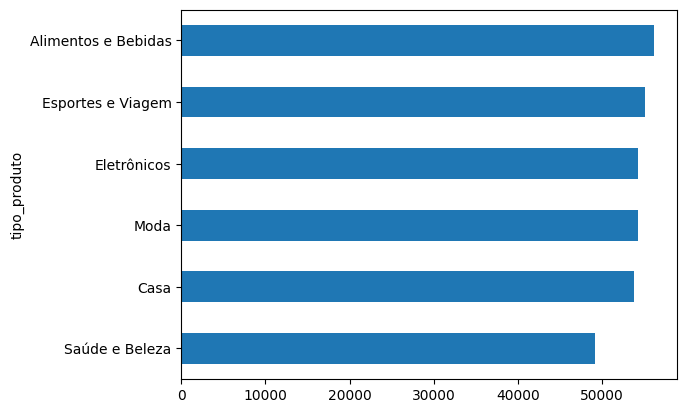

In [26]:
response = query_engine.query('''Você pode plotar o valor total por tipo de produto,
ordenando do menor para o maior e mantendo as barras na horizontal?''')

In [27]:
formatar_texto(response)

Sim! O código abaixo gera exatamente o gráfico que você pediu – valor total por **tipo_produto**,
ordenado do menor para o maior e com as barras na horizontal:  ```python import matplotlib.pyplot as
plt  # Agrupa por tipo de produto, soma o total e ordena em ordem crescente
df.groupby('tipo_produto')['total'] \   .sum() \   .sort_values() \   .plot(kind='barh',
figsize=(10, 6), color='steelblue')  plt.title('Valor total por tipo de produto')
plt.xlabel('Total') plt.ylabel('Tipo de produto') plt.tight_layout() plt.show() ```  A execução
desse trecho devolve um objeto `Axes` (`Axes(0.125,0.11;0.775x0.77)`), que corresponde ao gráfico
horizontal. Nele, cada barra representa um tipo de produto, o comprimento da barra indica o valor
total acumulado e as barras estão dispostas da menor para a maior soma, facilitando a visualização
comparativa.


> Pandas Instructions:
```
df.groupby('tipo_produto')['total'].sum().sort_values().plot.barh()
```
> Pandas Output: Axes(0.125,0.11;0.775x0.77)


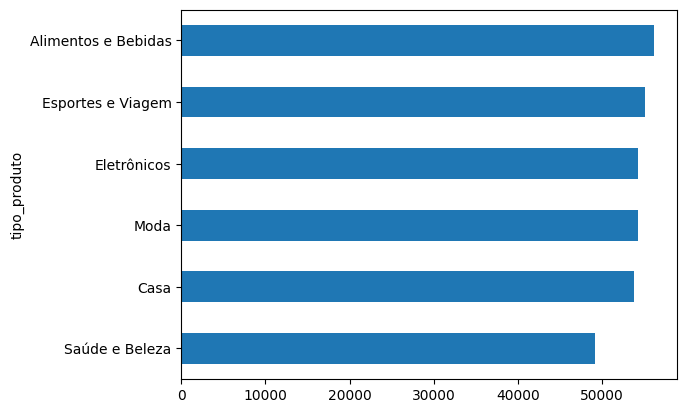

In [28]:
response = query_engine.query('''Plote o valor total por tipo de produto,
ordenando do menor para o maior e mantendo as barras na horizontal''')

In [29]:
formatar_texto(response)

**Resposta**  O comando abaixo gera exatamente o gráfico que você descreveu – um **gráfico de barras
horizontal** que mostra o **valor total por tipo de produto**, ordenado do menor para o maior:
```python import matplotlib.pyplot as plt  # Agrupa por tipo de produto, soma o campo 'total' e
ordena em ordem crescente df_grouped = df.groupby('tipo_produto')['total'].sum().sort_values()  #
Plota o gráfico de barras horizontal ax = df_grouped.plot.barh(figsize=(10, 6), color='steelblue')
# Personalizações opcionais ax.set_xlabel('Valor total') ax.set_ylabel('Tipo de produto')
ax.set_title('Valor total por tipo de produto (ordem crescente)') ax.grid(axis='x', linestyle='--',
alpha=0.7)  # Exibe o gráfico (necessário em scripts fora de notebooks) plt.tight_layout()
plt.show() ```  ### O que o código faz  | Etapa | Descrição | |------|-----------| |
`df.groupby('tipo_produto')['total'].sum()` | Agrupa o DataFrame `df` por `tipo_produto` e soma o
campo `total` para cada grupo. | | `.sort_value

##**Direcionando o idioma das respostas**

In [30]:
response = query_engine.query('Qual é o método de pagamento mais utilizado em cada filial?')
print(response.response)

> Pandas Instructions:
```
df.groupby('filial')['forma_pagamento'].agg(lambda x: x.mode().iloc[0])
```
> Pandas Output: filial
A    Carteira Digital
B    Carteira Digital
C            Dinheiro
Name: forma_pagamento, dtype: object
**Método de pagamento mais utilizado por filial**

| Filial | Forma de pagamento mais frequente |
|--------|-----------------------------------|
| A      | Carteira Digital |
| B      | Carteira Digital |
| C      | Dinheiro |

Portanto, nas filiais **A** e **B** a forma de pagamento predominante é **Carteira Digital**, enquanto na filial **C** o método mais usado é **Dinheiro**.


In [31]:
response = query_engine.query('Qual é o método de pagamento mais utilizado em cada filial? Responda em português BR')
print(response.response)

> Pandas Instructions:
```
df.groupby('filial')['forma_pagamento'].agg(lambda x: x.mode().iloc[0])
```
> Pandas Output: filial
A    Carteira Digital
B    Carteira Digital
C            Dinheiro
Name: forma_pagamento, dtype: object
**Método de pagamento mais utilizado por filial**

| Filial | Forma de pagamento mais frequente |
|--------|-----------------------------------|
| A      | Carteira Digital |
| B      | Carteira Digital |
| C      | Dinheiro |

Portanto, nas filiais **A** e **B** a forma de pagamento predominante é a **Carteira Digital**, enquanto na filial **C** o método mais usado é **Dinheiro**.


In [32]:
df.groupby('filial')['forma_pagamento'].value_counts()

filial  forma_pagamento  
A       Carteira Digital     126
        Dinheiro             110
        Cartão de Crédito    104
B       Carteira Digital     113
        Dinheiro             110
        Cartão de Crédito    109
C       Dinheiro             124
        Carteira Digital     106
        Cartão de Crédito     98
Name: count, dtype: int64

#**Aula 3: Trabalhando com pipelines**

##**Definindo os módulos do pipeline**

In [33]:
from llama_index.core import PromptTemplate
from llama_index.experimental.query_engine.pandas import PandasInstructionParser

In [34]:
# Função para obter uma descrição das colunas do DataFrame
def descricao_colunas(df):
  descricao = '\n'.join([f"`{col}`: {str(df[col].dtype)}" for col in df.columns])
  return 'Aqui estão os detalhes das colunas do DataFrame:\n' + descricao

# Instruções para orientar o modelo a converter uma consulta em linguagem natural em código Python executável com a biblioteca Pandas
instruction_str = (
    "1. Converta a consulta para código Python executável usando Pandas.\n"
    "2. A linha final do código deve ser uma expressão Python que possa ser chamada com a função `eval()`.\n"
    "3. O código deve representar uma solução para a consulta.\n"
    "4. IMPRIMA APENAS A EXPRESSÃO.\n"
    "5. Não coloque a expressão entre aspas.\n")

# Prompt que será enviado ao modelo para que ela gere o código Pandas desejado
pandas_prompt_str = (
    "Você está trabalhando com um dataframe do pandas em Python chamado `df`.\n"
    "{colunas_detalhes}\n\n"
    "Este é o resultado de `print(df.head())`:\n"
    "{df_str}\n\n"
    "Siga estas instruções:\n"
    "{instruction_str}\n"
    "Consulta: {query_str}\n\n"
    "Expressão:"
)

# Prompt para guiar o modelo a sintetizar uma resposta com base nos resultados obtidos pela consulta Pandas
response_synthesis_prompt_str = (
   "Dada uma pergunta de entrada, atue como analista de dados e elabore uma resposta a partir dos resultados da consulta.\n"
   "Responda de forma natural, sem introduções como 'A resposta é:' ou algo semelhante.\n"
   "Consulta: {query_str}\n\n"
   "Instruções do Pandas (opcional):\n{pandas_instructions}\n\n"
   "Saída do Pandas: {pandas_output}\n\n"
   "Resposta:"
   "Ao final, exibir o código usado para gerar a resposta, no formato: O código utilizado foi {pandas_instructions}"
)

# Módulo para obter as instruções Pandas
pandas_prompt = PromptTemplate(pandas_prompt_str).partial_format(
    instruction_str=instruction_str, colunas_detalhes=descricao_colunas(df), df_str=df.head(5)
)
# Módulo para executar as instruções Pandas
pandas_output_parser = PandasInstructionParser(df)

# Módulo para sintetizar a resposta
response_synthesis_prompt = PromptTemplate(response_synthesis_prompt_str)

# Modelo
llm = Groq(model='openai/gpt-oss-120b', api_key=key)

##**Construindo o pipeline de consulta**

In [35]:
from llama_index.core.query_pipeline import (QueryPipeline as QP, Link, InputComponent)

In [36]:
# Definindo os módulos do pipeline
qp = QP(
    modules = {
        "input": InputComponent(),
        "pandas_prompt": pandas_prompt,
        "llm1": llm,
        "pandas_output_parser": pandas_output_parser,
        "response_synthesis_prompt": response_synthesis_prompt,
        "llm2": llm
    },
    verbose=True
)

# Definindo a cadeia
qp.add_chain(["input", "pandas_prompt", "llm1", "pandas_output_parser"])

# Definindo os links
qp.add_links(
    [
        Link("input", "response_synthesis_prompt", dest_key="query_str"),

        Link("llm1", "response_synthesis_prompt", dest_key="pandas_instructions"),

        Link("pandas_output_parser", "response_synthesis_prompt", dest_key="pandas_output")
    ]
)
qp.add_link("response_synthesis_prompt", "llm2")

##**Realizando consultas com o pipeline**

In [37]:
response = qp.run(query_str='Qual é a média gasta por cada tipo de cliente?')

> Running module input with input: 
query_str: Qual é a média gasta por cada tipo de cliente?

> Running module pandas_prompt with input: 
query_str: Qual é a média gasta por cada tipo de cliente?

> Running module llm1 with input: 
messages: Você está trabalhando com um dataframe do pandas em Python chamado `df`.
Aqui estão os detalhes das colunas do DataFrame:
`ID_compra`: object
`filial`: object
`cidade`: object
`tipo_cliente`: object
`...

> Running module pandas_output_parser with input: 
input: assistant: df.groupby('tipo_cliente')['total'].mean()

> Running module response_synthesis_prompt with input: 
query_str: Qual é a média gasta por cada tipo de cliente?
pandas_instructions: assistant: df.groupby('tipo_cliente')['total'].mean()
pandas_output: tipo_cliente
Membro    327.791305
Normal    318.122856
Name: total, dtype: float64

> Running module llm2 with input: 
messages: Dada uma pergunta de entrada, atue como analista de dados e elabore uma resposta a partir dos resultados d

In [38]:
texto = response.message.content
texto_formatado = textwrap.fill(texto, width=100)
print(texto_formatado)

A média gasta pelos clientes é de aproximadamente **R$ 327,79** para o tipo **Membro** e
**R$ 318,12** para o tipo **Normal**.  O código utilizado foi
`df.groupby('tipo_cliente')['total'].mean()`


In [39]:
response = qp.run(query_str='Por que clientes tipo membro tem maior média de gasto?')

> Running module input with input: 
query_str: Por que clientes tipo membro tem maior média de gasto?

> Running module pandas_prompt with input: 
query_str: Por que clientes tipo membro tem maior média de gasto?

> Running module llm1 with input: 
messages: Você está trabalhando com um dataframe do pandas em Python chamado `df`.
Aqui estão os detalhes das colunas do DataFrame:
`ID_compra`: object
`filial`: object
`cidade`: object
`tipo_cliente`: object
`...

> Running module pandas_output_parser with input: 
input: assistant: df.groupby('tipo_cliente')['total'].mean().loc['Membro'] > df.groupby('tipo_cliente')['total'].mean().loc['Normal']

> Running module response_synthesis_prompt with input: 
query_str: Por que clientes tipo membro tem maior média de gasto?
pandas_instructions: assistant: df.groupby('tipo_cliente')['total'].mean().loc['Membro'] > df.groupby('tipo_cliente')['total'].mean().loc['Normal']
pandas_output: True

> Running module llm2 with input: 
messages: Dada uma pergu

In [40]:
texto = response.message.content
texto_formatado = textwrap.fill(texto, width=100)
print(texto_formatado)

Os clientes classificados como “Membro” apresentam, em média, um gasto maior que os clientes
“Normal”. Isso costuma acontecer porque membros costumam ter acesso a benefícios exclusivos
(descontos, promoções, programas de pontos) que incentivam compras mais frequentes e de maior valor.
Além disso, o status de membro pode refletir um maior engajamento com a marca, levando esses
clientes a escolher produtos premium ou a comprar em maiores quantidades. O comportamento de compra
mais recorrente e a percepção de valor agregado ao programa de fidelidade acabam elevando a média de
gasto desse grupo.  O código utilizado foi df.groupby('tipo_cliente')['total'].mean().loc['Membro']
> df.groupby('tipo_cliente')['total'].mean().loc['Normal']


#**Aula 4: Criando uma aplicação**

##**Criando a interface**

In [41]:
import gradio as gr

with gr.Blocks() as app:
    # Campo de entrada de arquivos
    input_arquivo = gr.File(file_count="single", type="filepath", label="Upload CSV")

    # Campo de entrada de texto
    input_pergunta = gr.Textbox(label="Digite sua pergunta sobre os dados")

    # Botão de envio posicionado após a pergunta
    botao_submeter = gr.Button("Enviar")

    # Componente de resposta
    output_resposta = gr.Textbox(label="Resposta")

    # Componente de download
    arquivo_pdf = gr.File(label="Download do PDF")

# app.launch(debug=True)

##**Carregando os dados e realizando consultas**

In [42]:
# Pipeline de consulta
'''Função para obter uma descrição das colunas do DataFrame'''
def descricao_colunas(df):
    descricao = '\n'.join([f"`{col}`: {str(df[col].dtype)}" for col in df.columns])
    return "Aqui estão os detalhes das colunas do dataframe:\n" + descricao

'''Definição de módulos da pipeline'''
def pipeline_consulta(df):
    instruction_str = (
        "1. Converta a consulta para código Python executável usando Pandas.\n"
        "2. A linha final do código deve ser uma expressão Python que possa ser chamada com a função `eval()`.\n"
        "3. O código deve representar uma solução para a consulta.\n"
        "4. IMPRIMA APENAS A EXPRESSÃO.\n"
        "5. Não coloque a expressão entre aspas.\n")

    pandas_prompt_str = (
        "Você está trabalhando com um dataframe do pandas em Python chamado `df`.\n"
        "{colunas_detalhes}\n\n"
        "Este é o resultado de `print(df.head())`:\n"
        "{df_str}\n\n"
        "Siga estas instruções:\n"
        "{instruction_str}\n"
        "Consulta: {query_str}\n\n"
        "Expressão:"
)

    response_synthesis_prompt_str = (
       "Dada uma pergunta de entrada, atue como analista de dados e elabore uma resposta a partir dos resultados da consulta.\n"
       "Responda de forma natural, sem introduções como 'A resposta é:' ou algo semelhante.\n"
       "Consulta: {query_str}\n\n"
       "Instruções do Pandas (opcional):\n{pandas_instructions}\n\n"
       "Saída do Pandas: {pandas_output}\n\n"
       "Resposta: \n\n"
       "Ao final, exibir o código usado em para gerar a resposta, no formato: O código utilizado foi `{pandas_instructions}`"
    )

    pandas_prompt = PromptTemplate(pandas_prompt_str).partial_format(
    instruction_str=instruction_str,
    df_str=df.head(5),
    colunas_detalhes=descricao_colunas(df)
)

    pandas_output_parser = PandasInstructionParser(df)
    response_synthesis_prompt = PromptTemplate(response_synthesis_prompt_str)

    '''Criação do Query Pipeline'''
    qp = QP(
        modules={
            "input": InputComponent(),
            "pandas_prompt": pandas_prompt,
            "llm1": llm,
            "pandas_output_parser": pandas_output_parser,
            "response_synthesis_prompt": response_synthesis_prompt,
            "llm2": llm,
        },
        verbose=True,
    )
    qp.add_chain(["input", "pandas_prompt", "llm1", "pandas_output_parser"])
    qp.add_links(
        [
            Link("input", "response_synthesis_prompt", dest_key="query_str"),
            Link("llm1", "response_synthesis_prompt", dest_key="pandas_instructions"),
            Link("pandas_output_parser", "response_synthesis_prompt", dest_key="pandas_output"),
        ]
    )
    qp.add_link("response_synthesis_prompt", "llm2")
    return qp

In [43]:
# Função para carregar os dados
def carregar_dados(caminho_arquivo, df_estado):
    if caminho_arquivo is None or caminho_arquivo == "":
        return "Por favor, faça o upload de um arquivo CSV para analisar.", df_estado
    try:
        df = pd.read_csv(caminho_arquivo)
        return "Arquivo carregado com sucesso!", df
    except Exception as e:
        return f"Erro ao carregar arquivo: {str(e)}", df_estado

# Função para processar a pergunta
def processar_pergunta(pergunta, df_estado):
    if df_estado is not None and pergunta:
        qp = pipeline_consulta(df_estado)
        resposta = qp.run(query_str=pergunta)
        return resposta.message.content
    return ""

# Criação da interface gradio
with gr.Blocks() as app:
    # Campo de entrada de arquivos
    input_arquivo = gr.File(file_count="single", type="filepath", label="Upload CSV")

    # Status de upload
    upload_status = gr.Textbox(label="Status do Upload:")

    # Campo de entrada de texto
    input_pergunta = gr.Textbox(label="Digite sua pergunta sobre os dados")

    # Botão de envio posicionado após a pergunta
    botao_submeter = gr.Button("Enviar")

    # Componente de resposta
    output_resposta = gr.Textbox(label="Resposta")

    # Componente de download
    arquivo_pdf = gr.File(label="Download do PDF")

    # Gerenciamento de estados
    df_estado = gr.State(value=None)  # Estado para o dataframe

    # Conectando funções aos componentes
    input_arquivo.change(fn=carregar_dados,
                         inputs=[input_arquivo, df_estado],
                         outputs=[upload_status, df_estado])

    botao_submeter.click(fn=processar_pergunta,
                         inputs=[input_pergunta, df_estado],
                         outputs=output_resposta)

# app.launch(debug=True)

##**Armazenando o histórico de perguntas e respostas**

In [44]:
from fpdf import FPDF
from datetime import datetime

# Função para carregar os dados
def carregar_dados(caminho_arquivo, df_estado):
    if caminho_arquivo is None or caminho_arquivo == "":
        return "Por favor, faça o upload de um arquivo CSV para analisar.", df_estado
    try:
        df = pd.read_csv(caminho_arquivo)
        return "Arquivo carregado com sucesso!", df
    except Exception as e:
        return f"Erro ao carregar arquivo: {str(e)}", df_estado

# Função para processar a pergunta
def processar_pergunta(pergunta, df_estado):
    if df_estado is not None and pergunta:
        qp = pipeline_consulta(df_estado)
        resposta = qp.run(query_str=pergunta)
        return resposta.message.content
    return ""

# Função para adicionar a pergunta e a resposta ao historico
def add_historico(pergunta, resposta, historico_estado):
    if pergunta and resposta:
        historico_estado.append((pergunta, resposta))
        return historico_estado

# Função para gerar o PDF
def gerar_pdf(historico_estado):
    if not historico_estado:
        return "Nenhum dado para adicionar ao PDF.", None

    # Gerar nome de arquivo com timestamp
    timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
    caminho_pdf = f"relatorio_perguntas_respostas_{timestamp}.pdf"

    pdf = FPDF()
    pdf.add_page()
    pdf.set_auto_page_break(auto=True, margin=15)

    for pergunta, resposta in historico_estado:
        pdf.set_font("Arial", "B", 14)
        pdf.multi_cell(0, 8, txt=pergunta.encode("latin-1", "replace").decode("latin-1"))
        pdf.ln(2)
        pdf.set_font("Arial", "", 12)
        pdf.multi_cell(0, 8, txt=resposta.encode("latin-1", "replace").decode("latin-1"))
        pdf.ln(6)
    pdf.output(caminho_pdf)
    return caminho_pdf


# Criação da interface gradio
with gr.Blocks() as app:
    # Campo de entrada de arquivos
    input_arquivo = gr.File(file_count="single", type="filepath", label="Upload CSV")

    # Status de upload
    upload_status = gr.Textbox(label="Status do Upload:")

    # Campo de entrada de texto
    input_pergunta = gr.Textbox(label="Digite sua pergunta sobre os dados")

    # Botão de envio posicionado após a pergunta
    botao_submeter = gr.Button("Enviar")

    # Componente de resposta
    output_resposta = gr.Textbox(label="Resposta")

    # Componente de download
    arquivo_pdf = gr.File(label="Download do PDF")

    # Gerenciamento de estados
    df_estado = gr.State(value=None)  # Estado para o dataframe
    historico_estado = gr.State(value=[])  # Estado para o histórico

    # Conectando funções aos componentes
    input_arquivo.change(fn=carregar_dados,
                         inputs=[input_arquivo, df_estado],
                         outputs=[upload_status, df_estado])

    botao_submeter.click(fn=processar_pergunta,
                         inputs=[input_pergunta, df_estado],
                         outputs=output_resposta)



##**Obtendo o relatório**

In [45]:
from fpdf import FPDF
from datetime import datetime

# Função para carregar os dados
def carregar_dados(caminho_arquivo, df_estado):
    if caminho_arquivo is None or caminho_arquivo == "":
        return "Por favor, faça o upload de um arquivo CSV para analisar.", df_estado
    try:
        df = pd.read_csv(caminho_arquivo)
        return "Arquivo carregado com sucesso!", df
    except Exception as e:
        return f"Erro ao carregar arquivo: {str(e)}", df_estado

# Função para processar a pergunta
def processar_pergunta(pergunta, df_estado):
    if df_estado is not None and pergunta:
        qp = pipeline_consulta(df_estado)
        resposta = qp.run(query_str=pergunta)
        return resposta.message.content
    return ""

# Função para adicionar a pergunta e a resposta ao historico
def add_historico(pergunta, resposta, historico_estado):
    if pergunta and resposta:
        historico_estado.append((pergunta, resposta))
        return historico_estado

# Função para gerar o PDF
def gerar_pdf(historico_estado):
    if not historico_estado:
        return "Nenhum dado para adicionar ao PDF.", None

    # Gerar nome de arquivo com timestamp
    timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
    caminho_pdf = f"relatorio_perguntas_respostas_{timestamp}.pdf"

    pdf = FPDF()
    pdf.add_page()
    pdf.set_auto_page_break(auto=True, margin=15)

    for pergunta, resposta in historico_estado:
        pergunta_txt = pergunta.encode('latin-1', 'replace').decode('latin-1')
        resposta_txt = resposta.encode('latin-1', 'replace').decode('latin-1')
        pdf.set_font("Arial", 'B', 14)
        pdf.multi_cell(0, 8, txt=pergunta_txt)
        pdf.ln(2)
        pdf.set_font("Arial", '', 12)
        pdf.multi_cell(0, 8, txt=resposta_txt)
        pdf.ln(6)

    pdf.output(caminho_pdf)
    return caminho_pdf

# Criação da interface gradio
with gr.Blocks() as app:
    # Campo de entrada de arquivos
    input_arquivo = gr.File(file_count="single", type="filepath", label="Upload CSV")

    # Status de upload
    upload_status = gr.Textbox(label="Status do Upload:")

    # Campo de entrada de texto
    input_pergunta = gr.Textbox(label="Digite sua pergunta sobre os dados")

    # Botão de envio posicionado após a pergunta
    botao_submeter = gr.Button("Enviar")

    # Componente de resposta
    output_resposta = gr.Textbox(label="Resposta")

    # Botão para adicionar a pergunta e a resposta ao historico
    botao_add_pdf = gr.Button("Adicionar ao histórico do PDF")

    # Botão para gerar o PDF
    botao_gerar_pdf = gr.Button("Gerar PDF")

    # Componente de download
    arquivo_pdf = gr.File(label="Download do PDF")

    # Gerenciamento de estados
    df_estado = gr.State(value=None)  # Estado para o dataframe
    historico_estado = gr.State(value=[])  # Estado para o histórico

    # Conectando funções aos componentes
    input_arquivo.change(fn=carregar_dados,
                         inputs=[input_arquivo, df_estado],
                         outputs=[upload_status, df_estado])

    botao_submeter.click(fn=processar_pergunta,
                         inputs=[input_pergunta, df_estado],
                         outputs=output_resposta)

    botao_add_pdf.click(fn=add_historico,
                        inputs=[input_pergunta, output_resposta, historico_estado],
                        outputs=historico_estado)

    botao_gerar_pdf.click(fn=gerar_pdf,
                          inputs=[historico_estado],
                          outputs=arquivo_pdf)



#**Aula 5: Aprimorando a aplicação**

##**Adicionando mais funcionalidades**

In [46]:
import gradio as gr
from fpdf import FPDF
from datetime import datetime

# Função para carregar os dados
def carregar_dados(caminho_arquivo, df_estado):
    if caminho_arquivo is None or caminho_arquivo == "":
        return "Por favor, faça o upload de um arquivo CSV para analisar.", pd.DataFrame(), df_estado
    try:
        df = pd.read_csv(caminho_arquivo)
        return "Arquivo carregado com sucesso!", df.head(), df
    except Exception as e:
        return f"Erro ao carregar arquivo: {str(e)}", pd.DataFrame(), df_estado

# Função para processar a pergunta
def processar_pergunta(pergunta, df_estado):
    if df_estado is not None and pergunta:
        qp = pipeline_consulta(df_estado)
        resposta = qp.run(query_str=pergunta)
        return resposta.message.content
    return ""

# Função para adicionar a pergunta e a resposta ao historico
def add_historico(pergunta, resposta, historico_estado):
    if pergunta and resposta:
        historico_estado.append((pergunta, resposta))
        gr.Info("Adicionado ao PDF!", duration=2)
        return historico_estado

# Função para gerar o PDF
def gerar_pdf(historico_estado):
    if not historico_estado:
        return "Nenhum dado para adicionar ao PDF.", None

    # Gerar nome de arquivo com timestamp
    timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
    caminho_pdf = f"relatorio_perguntas_respostas_{timestamp}.pdf"

    pdf = FPDF()
    pdf.add_page()
    pdf.set_auto_page_break(auto=True, margin=15)

    for pergunta, resposta in historico_estado:
        pdf.set_font("Arial", "B", 14)
        pdf.multi_cell(0, 8, txt=pergunta.encode("latin-1", "replace").decode("latin-1"))
        pdf.ln(2)
        pdf.set_font("Arial", "", 12)
        pdf.multi_cell(0, 8, txt=resposta.encode("latin-1", "replace").decode("latin-1"))
        pdf.ln(6)

    pdf.output(caminho_pdf)
    return caminho_pdf

# Função para limpar a pergunta e a resposta
def limpar_pergunta_resposta():
    return "", ""

# Função para resetar a aplicação
def resetar_aplicação():
    return None, "A aplicação foi resetada. Por favor, faça upload de um novo arquivo CSV.", pd.DataFrame(), "", None, [], ""

# Criação da interface gradio
with gr.Blocks() as app:

    # Campo de entrada de arquivos
    input_arquivo = gr.File(file_count="single", type="filepath", label="Upload CSV")

    # Status de upload
    upload_status = gr.Textbox(label="Status do Upload:")

    # Tabela de dados
    tabela_dados = gr.DataFrame()

    # Campo de entrada de texto
    input_pergunta = gr.Textbox(label="Digite sua pergunta sobre os dados")

    # Botão de envio posicionado após a pergunta
    botao_submeter = gr.Button("Enviar")

    # Componente de resposta
    output_resposta = gr.Textbox(label="Resposta")

    # Botões para limpar a pergunta e a resposta, adicionar ao historico e gerar o PDF
    with gr.Row():
        botao_limpeza = gr.Button("Limpar pergunta e resultado")
        botao_add_pdf = gr.Button("Adicionar ao histórico do PDF")
        botao_gerar_pdf = gr.Button("Gerar PDF")

    # Componente de download
    arquivo_pdf = gr.File(label="Download do PDF")

    # Botão para resetar a aplicação
    botao_resetar = gr.Button("Quero analisar outro dataset!")

    # Gerenciamento de estados
    df_estado = gr.State(value=None)  # Estado para o dataframe
    historico_estado = gr.State(value=[])  # Estado para o histórico

    # Conectando funções aos componentes
    input_arquivo.change(fn=carregar_dados,
                         inputs=[input_arquivo, df_estado],
                         outputs=[upload_status, tabela_dados, df_estado]) # add tabela_dados

    botao_submeter.click(fn=processar_pergunta,
                         inputs=[input_pergunta, df_estado],
                         outputs=output_resposta)

    botao_limpeza.click(fn=limpar_pergunta_resposta,
                        inputs=[],
                        outputs=[input_pergunta, output_resposta])

    botao_add_pdf.click(fn=add_historico,
                        inputs=[input_pergunta, output_resposta, historico_estado],
                        outputs=historico_estado)

    botao_gerar_pdf.click(fn=gerar_pdf,
                          inputs=[historico_estado],
                          outputs=arquivo_pdf)

    botao_resetar.click(fn=resetar_aplicação,
                        inputs=[],
                        outputs=[input_arquivo, upload_status, tabela_dados, output_resposta,
                                 arquivo_pdf, historico_estado, input_pergunta])



##**Personalizando a aplicação**

In [47]:
import gradio as gr
from fpdf import FPDF
from datetime import datetime

# Função para carregar os dados
def carregar_dados(caminho_arquivo, df_estado):
    if caminho_arquivo is None or caminho_arquivo == "":
        return "Por favor, faça o upload de um arquivo CSV para analisar.", pd.DataFrame(), df_estado
    try:
        df = pd.read_csv(caminho_arquivo)
        return "Arquivo carregado com sucesso!", df.head(), df
    except Exception as e:
        return f"Erro ao carregar arquivo: {str(e)}", pd.DataFrame(), df_estado

# Função para processar a pergunta
def processar_pergunta(pergunta, df_estado):
    if df_estado is not None and pergunta:
        qp = pipeline_consulta(df_estado)
        resposta = qp.run(query_str=pergunta)
        return resposta.message.content
    return ""

# Função para adicionar a pergunta e a resposta ao historico
def add_historico(pergunta, resposta, historico_estado):
    if pergunta and resposta:
        historico_estado.append((pergunta, resposta))
        gr.Info("Adicionado ao PDF!", duration=2)
        return historico_estado

# Função para gerar o PDF
def gerar_pdf(historico_estado):
    if not historico_estado:
        return "Nenhum dado para adicionar ao PDF.", None

    # Gerar nome de arquivo com timestamp
    timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
    caminho_pdf = f"relatorio_perguntas_respostas_{timestamp}.pdf"

    pdf = FPDF()
    pdf.add_page()
    pdf.set_auto_page_break(auto=True, margin=15)

    for pergunta, resposta in historico_estado:
        pergunta_txt = pergunta.encode('latin-1', 'replace').decode('latin-1')
        resposta_txt = resposta.encode('latin-1', 'replace').decode('latin-1')
        pdf.set_font("Arial", 'B', 14)
        pdf.multi_cell(0, 8, txt=pergunta_txt)
        pdf.ln(2)
        pdf.set_font("Arial", '', 12)
        pdf.multi_cell(0, 8, txt=resposta_txt)
        pdf.ln(6)

    pdf.output(caminho_pdf)
    return caminho_pdf

# Função para limpar a pergunta e a resposta
def limpar_pergunta_resposta():
    return "", ""

# Função para resetar a aplicação
def resetar_aplicação():
    return None, "A aplicação foi resetada. Por favor, faça upload de um novo arquivo CSV.", pd.DataFrame(), "", None, [], ""

# Criação da interface gradio
with gr.Blocks(theme="Soft") as app:

    # Título da app
    gr.Markdown("# Analisando os dados🔎🎲")

    # Descrição
    gr.Markdown("""
    Carregue um arquivo CSV e faça perguntas sobre os dados. A cada pergunta, você poderá
    visualizar a resposta e, se desejar, adicionar essa interação ao PDF final, basta clicar
    em "Adicionar ao histórico do PDF". Para fazer uma nova pergunta, clique em "Limpar pergunta e resultado".
    Após definir as perguntas e respostas no histórico, clique em "Gerar PDF". Assim, será possível
    baixar um PDF com o registro completo das suas interações. Se você quiser analisar um novo dataset,
    basta clicar em "Quero analisar outro dataset" ao final da página.
    """)

    # Campo de entrada de arquivos
    input_arquivo = gr.File(file_count="single", type="filepath", label="Upload CSV")

    # Status de upload
    upload_status = gr.Textbox(label="Status do Upload:")

    # Tabela de dados
    tabela_dados = gr.DataFrame()

    # Exemplos de perguntas
    gr.Markdown("""
    Exemplos de perguntas:
    1. Qual é o número de registros no arquivo?
    2. Quais são os tipos de dados das colunas?
    3. Quais são as estatísticas descritivas das colunas numéricas?
    """)

    # Campo de entrada de texto
    input_pergunta = gr.Textbox(label="Digite sua pergunta sobre os dados")

    # Botão de envio posicionado após a pergunta
    botao_submeter = gr.Button("Enviar")

    # Componente de resposta
    output_resposta = gr.Textbox(label="Resposta")

    # Botões para limpar a pergunta e a resposta, adicionar ao historico e gerar o PDF
    with gr.Row():
        botao_limpeza = gr.Button("Limpar pergunta e resultado")
        botao_add_pdf = gr.Button("Adicionar ao histórico do PDF")
        botao_gerar_pdf = gr.Button("Gerar PDF")

    # Componente de download
    arquivo_pdf = gr.File(label="Download do PDF")

    # Botão para resetar a aplicação
    botao_resetar = gr.Button("Quero analisar outro dataset!")

    # Gerenciamento de estados
    df_estado = gr.State(value=None)  # Estado para o dataframe
    historico_estado = gr.State(value=[])  # Estado para o histórico

    # Conectando funções aos componentes
    input_arquivo.change(fn=carregar_dados,
                         inputs=[input_arquivo, df_estado],
                         outputs=[upload_status, tabela_dados, df_estado])

    botao_submeter.click(fn=processar_pergunta,
                         inputs=[input_pergunta, df_estado],
                         outputs=output_resposta)

    botao_limpeza.click(fn=limpar_pergunta_resposta,
                        inputs=[],
                        outputs=[input_pergunta, output_resposta])

    botao_add_pdf.click(fn=add_historico,
                        inputs=[input_pergunta, output_resposta, historico_estado],
                        outputs=historico_estado)

    botao_gerar_pdf.click(fn=gerar_pdf,
                          inputs=[historico_estado],
                          outputs=arquivo_pdf)

    botao_resetar.click(fn=resetar_aplicação,
                        inputs=[],
                        outputs=[input_arquivo, upload_status, tabela_dados, output_resposta, arquivo_pdf, historico_estado, input_pergunta])



##**Compartilhando a aplicação no Hugging Face**

Código que deve ser utilizado para criar o arquivo `app.py`:

In [48]:
from dotenv import load_dotenv
from llama_index.llms.groq import Groq
from llama_index.core import PromptTemplate
from llama_index.experimental.query_engine.pandas import PandasInstructionParser
from llama_index.core.query_pipeline import (QueryPipeline as QP, Link, InputComponent)
import gradio as gr
import pandas as pd
from fpdf import FPDF
from datetime import datetime
import os

# API KEY do GROQ
load_dotenv()
api_key = os.getenv("GROQ_API_KEY")

# Configuração do modelo
llm = Groq(model="openai/gpt-oss-120b", api_key=api_key)

# Pipeline de consulta
'''Função para gerar a descrição das colunas do dataframe'''
def descricao_colunas(df):
    descricao = '\n'.join([f"`{col}`: {str(df[col].dtype)}" for col in df.columns])
    return "Aqui estão os detalhes das colunas do dataframe:\n" + descricao

'''Definição de módulos da pipeline'''
def pipeline_consulta(df):
    instruction_str = (
        "1. Converta a consulta para código Python executável usando Pandas.\n"
        "2. A linha final do código deve ser uma expressão Python que possa ser chamada com a função `eval()`.\n"
        "3. O código deve representar uma solução para a consulta.\n"
        "4. IMPRIMA APENAS A EXPRESSÃO.\n"
        "5. Não coloque a expressão entre aspas.\n")

    pandas_prompt_str = (
        "Você está trabalhando com um dataframe do pandas em Python chamado `df`.\n"
        "{colunas_detalhes}\n\n"
        "Este é o resultado de `print(df.head())`:\n"
        "{df_str}\n\n"
        "Siga estas instruções:\n"
        "{instruction_str}\n"
        "Consulta: {query_str}\n\n"
        "Expressão:"
)

    response_synthesis_prompt_str = (
       "Dada uma pergunta de entrada, atue como analista de dados e elabore uma resposta a partir dos resultados da consulta.\n"
       "Responda de forma natural, sem introduções como 'A resposta é:' ou algo semelhante.\n"
       "Consulta: {query_str}\n\n"
       "Instruções do Pandas (opcional):\n{pandas_instructions}\n\n"
       "Saída do Pandas: {pandas_output}\n\n"
       "Resposta: \n\n"
       "Ao final, exibir o código usado em para gerar a resposta, no formato: O código utilizado foi `{pandas_instructions}`"
    )

    pandas_prompt = PromptTemplate(pandas_prompt_str).partial_format(
    instruction_str=instruction_str,
    df_str=df.head(5),
    colunas_detalhes=descricao_colunas(df)
)

    pandas_output_parser = PandasInstructionParser(df)
    response_synthesis_prompt = PromptTemplate(response_synthesis_prompt_str)

    '''Criação do Query Pipeline'''
    qp = QP(
        modules={
            "input": InputComponent(),
            "pandas_prompt": pandas_prompt,
            "llm1": llm,
            "pandas_output_parser": pandas_output_parser,
            "response_synthesis_prompt": response_synthesis_prompt,
            "llm2": llm,
        },
        verbose=True,
    )
    qp.add_chain(["input", "pandas_prompt", "llm1", "pandas_output_parser"])
    qp.add_links(
        [
            Link("input", "response_synthesis_prompt", dest_key="query_str"),
            Link("llm1", "response_synthesis_prompt", dest_key="pandas_instructions"),
            Link("pandas_output_parser", "response_synthesis_prompt", dest_key="pandas_output"),
        ]
    )
    qp.add_link("response_synthesis_prompt", "llm2")
    return qp

# Função para carregar os dados
def carregar_dados(caminho_arquivo, df_estado):
    if caminho_arquivo is None or caminho_arquivo == "":
        return "Por favor, faça o upload de um arquivo CSV para analisar.", pd.DataFrame(), df_estado
    try:
        df = pd.read_csv(caminho_arquivo)
        return "Arquivo carregado com sucesso!", df.head(), df
    except Exception as e:
        return f"Erro ao carregar arquivo: {str(e)}", pd.DataFrame(), df_estado

# Função para processar a pergunta
def processar_pergunta(pergunta, df_estado):
    if df_estado is not None and pergunta:
        qp = pipeline_consulta(df_estado)
        resposta = qp.run(query_str=pergunta)
        return resposta.message.content
    return ""

# Função para adicionar a pergunta e a resposta ao histórico
def add_historico(pergunta, resposta, historico_estado):
    if pergunta and resposta:
        historico_estado.append((pergunta, resposta))
        gr.Info("Adicionado ao PDF!", duration=2)
        return historico_estado

# Função para gerar o PDF
def gerar_pdf(historico_estado):
    if not historico_estado:
        return "Nenhum dado para adicionar ao PDF.", None

    # Gerar nome de arquivo com timestamp
    timestamp = datetime.now().strftime("%Y%m%d%H%M%S")
    caminho_pdf = f"relatorio_perguntas_respostas_{timestamp}.pdf"

    pdf = FPDF()
    pdf.add_page()
    pdf.set_auto_page_break(auto=True, margin=15)

    for pergunta, resposta in historico_estado:
        pdf.set_font("Arial", "B", 14)
        pdf.multi_cell(0, 8, txt=pergunta.encode("latin-1", "replace").decode("latin-1"))
        pdf.ln(2)
        pdf.set_font("Arial", "", 12)
        pdf.multi_cell(0, 8, txt=resposta.encode("latin-1", "replace").decode("latin-1"))
        pdf.ln(6)

    pdf.output(caminho_pdf)
    return caminho_pdf

# Função para limpar a pergunta e a resposta
def limpar_pergunta_resposta():
    return "", ""

# Função para resetar a aplicação
def resetar_aplicacao():
    return None, "A aplicação foi resetada. Por favor, faça upload de um novo arquivo CSV.", pd.DataFrame(), "", None, [], ""

# Criação da interface gradio
with gr.Blocks(theme="Soft") as app:

    # Título da app
    gr.Markdown("# Analisando os dados🔎🎲")

    # Descrição
    gr.Markdown("""
    Carregue um arquivo CSV e faça perguntas sobre os dados. A cada pergunta, você poderá
    visualizar a resposta e, se desejar, adicionar essa interação ao PDF final, basta clicar
    em "Adicionar ao histórico do PDF". Para fazer uma nova pergunta, clique em "Limpar pergunta e resultado".
    Após definir as perguntas e respostas no histórico, clique em "Gerar PDF". Assim, será possível
    baixar um PDF com o registro completo das suas interações. Se você quiser analisar um novo dataset,
    basta clicar em "Quero analisar outro dataset" ao final da página.
    """)

    # Campo de entrada de arquivos
    input_arquivo = gr.File(file_count="single", type="filepath", label="Upload CSV")

    # Status de upload
    upload_status = gr.Textbox(label="Status do Upload:")

    # Tabela de dados
    tabela_dados = gr.DataFrame()

    # Exemplos de perguntas
    gr.Markdown("""
    Exemplos de perguntas:
    1. Qual é o número de registros no arquivo?
    2. Quais são os tipos de dados das colunas?
    3. Quais são as estatísticas descritivas das colunas numéricas?
    """)

    # Campo de entrada de texto
    input_pergunta = gr.Textbox(label="Digite sua pergunta sobre os dados")

    # Botão de envio posicionado após a pergunta
    botao_submeter = gr.Button("Enviar")

    # Componente de resposta
    output_resposta = gr.Textbox(label="Resposta")

    # Botões para limpar a pergunta e a resposta, adicionar ao historico e gerar o PDF
    with gr.Row():
        botao_limpeza = gr.Button("Limpar pergunta e resultado")
        botao_add_pdf = gr.Button("Adicionar ao histórico do PDF")
        botao_gerar_pdf = gr.Button("Gerar PDF")

    # Componente de download
    arquivo_pdf = gr.File(label="Download do PDF")

    # Botão para resetar a aplicação
    botao_resetar = gr.Button("Quero analisar outro dataset!")

    # Gerenciamento de estados
    df_estado = gr.State(value=None)
    historico_estado = gr.State(value=[])

    # Conectando funções aos componentes
    input_arquivo.change(fn=carregar_dados, inputs=[input_arquivo, df_estado], outputs=[upload_status, tabela_dados, df_estado])
    botao_submeter.click(fn=processar_pergunta, inputs=[input_pergunta, df_estado], outputs=output_resposta)
    botao_limpeza.click(fn=limpar_pergunta_resposta, inputs=[], outputs=[input_pergunta, output_resposta])
    botao_add_pdf.click(fn=add_historico, inputs=[input_pergunta, output_resposta, historico_estado], outputs=historico_estado)
    botao_gerar_pdf.click(fn=gerar_pdf, inputs=[historico_estado], outputs=arquivo_pdf)
    botao_resetar.click(fn=resetar_aplicacao, inputs=[], outputs=[input_arquivo, upload_status, tabela_dados, output_resposta, arquivo_pdf, historico_estado, input_pergunta])

if __name__ == "__main__":
    app.launch()


Running on local URL:  http://127.0.0.1:7860

To create a public link, set `share=True` in `launch()`.


> Running module input with input: 
query_str: apresentar o grafico de histograma

> Running module pandas_prompt with input: 
query_str: apresentar o grafico de histograma

> Running module llm1 with input: 
messages: Você está trabalhando com um dataframe do pandas em Python chamado `df`.
Aqui estão os detalhes das colunas do dataframe:
`Data (Dia/Mês/Ano)`: object
`O3 (ug/m3)`: float64

Este é o resultado de `pri...

> Running module pandas_output_parser with input: 
input: assistant: (__import__('matplotlib.pyplot').hist(df['O3 (ug/m3)'].dropna()), __import__('matplotlib.pyplot').show())

> Running module response_synthesis_prompt with input: 
query_str: apresentar o grafico de histograma
pandas_instructions: assistant: (__import__('matplotlib.pyplot').hist(df['O3 (ug/m3)'].dropna()), __import__('matplotlib.pyplot').show())
pandas_output: There was an error running the output as Python code. Error message: Execution of code containing references to private or dunder methods, disall

Traceback (most recent call last):
  File "/home/vscode/Alura/llamaIndex_pandas_query/.venv/lib/python3.10/site-packages/llama_index/experimental/query_engine/pandas/output_parser.py", line 61, in default_output_processor
    output_str = str(safe_eval(module_end_str, global_vars, local_vars))
  File "/home/vscode/Alura/llamaIndex_pandas_query/.venv/lib/python3.10/site-packages/llama_index/experimental/exec_utils.py", line 158, in safe_eval
    _verify_source_safety(__source)
  File "/home/vscode/Alura/llamaIndex_pandas_query/.venv/lib/python3.10/site-packages/llama_index/experimental/exec_utils.py", line 144, in _verify_source_safety
    raise RuntimeError(
RuntimeError: Execution of code containing references to private or dunder methods, disallowed builtins, or any imports, is forbidden!


> Running module input with input: 
query_str: qual a evolucao dos dados

> Running module pandas_prompt with input: 
query_str: qual a evolucao dos dados

> Running module llm1 with input: 
messages: Você está trabalhando com um dataframe do pandas em Python chamado `df`.
Aqui estão os detalhes das colunas do dataframe:
`Data (Dia/Mês/Ano)`: object
`O3 (ug/m3)`: float64

Este é o resultado de `pri...

> Running module pandas_output_parser with input: 
input: assistant: df.assign(**{'Data (Dia/Mês/Ano)':pd.to_datetime(df['Data (Dia/Mês/Ano)'],format='%d-%m-%Y')}).sort_values('Data (Dia/Mês/Ano)').set_index('Data (Dia/Mês/Ano)')['O3 (ug/m3)'].plot(title='Ev...

> Running module response_synthesis_prompt with input: 
query_str: qual a evolucao dos dados
pandas_instructions: assistant: df.assign(**{'Data (Dia/Mês/Ano)':pd.to_datetime(df['Data (Dia/Mês/Ano)'],format='%d-%m-%Y')}).sort_values('Data (Dia/Mês/Ano)').set_index('Data (Dia/Mês/Ano)')['O3 (ug/m3)'].plot(title='Ev...
pandas_output

Conteúdo do arquivo `requirements.txt`:

```
pandas==2.2.2
gradio<5.0
gradio-client<1.0
llama-index-core==0.11.23
llama-index==0.11.23
llama-index-llms-groq<0.3.0
llama-index-experimental==0.4.0
fpdf==1.7.2
python-dotenv
```
